### Build basic chatbot with langgraph

1. What is LangGraph?

LangGraph is a framework for building stateful, multi-step AI workflows/agents.

The basic idea is:

Input → Node → Node → Node → Output
          ↑
        State

A graph consists mainly of:

State → data shared between nodes
Nodes → functions that perform work
Edges → decide where to go next
Graph → connects everything together
2. State

State defines the information that flows through your graph.

from typing import TypedDict

class State(TypedDict):
    messages: list
    name: str
    age: int

Think of State as the common data structure/memory of the graph.

At any point, the graph has something like:

{
    "messages": [...],
    "name": "Gunjan",
    "age": 25
}
3. Node

A node is normally just a Python function.

def chatbot(state: State):
    response = llm.invoke(state["messages"])

    return {
        "messages": [response]
    }

Here:

state: State

means the function receives the current graph state.

And:

state["messages"]

gets the messages field from that state.

4. Node doesn't need to return the whole State

Suppose State has:

class State(TypedDict):
    messages: list
    name: str
    age: int

Your node can return only:

return {
    "messages": [response]
}

It doesn't have to return:

return {
    "messages": [...],
    "name": state["name"],
    "age": state["age"]
}

The returned dictionary represents the state update.

Think:

state       = current complete state
return      = changes to the state
5. Graph

You create a graph using StateGraph.

from langgraph.graph import StateGraph

graph_builder = StateGraph(State)

Then add nodes:

graph_builder.add_node("chatbot", chatbot)
6. Edges

Edges tell LangGraph which node should execute next.

For example:

graph_builder.set_entry_point("chatbot")

means:

START
  ↓
chatbot

And:

graph_builder.set_finish_point("chatbot")

means:

chatbot
  ↓
END

So:

graph_builder.set_entry_point("chatbot")
graph_builder.set_finish_point("chatbot")

creates:

START → chatbot → END
7. Compile

Before running the graph, compile it:

graph = graph_builder.compile()

Think of this as:

Graph definition
      ↓
    compile
      ↓
Runnable graph

You generally invoke the compiled graph, not the builder.

8. Invoke

You start the graph using:

result = graph.invoke({
    "messages": [
        HumanMessage(content="Hello")
    ]
})

The dictionary is the initial state/input.

You generally provide the initial values needed by the workflow's starting node(s).

For example:

graph.invoke(initial_state)
             ↓
       starting state
             ↓
         first node
             ↓
       state update
             ↓
        next node

In [ ]:
import os
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, add_messages,START,END
from langchain.chat_models import init_chat_model
from typing import Annotated

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
# here we are defining state means what state structure should look like 
class State(TypedDict):
    #  here annoted just simply bind add_meesgages which does instead if replacing it add in existing list
    messages: Annotated[list,add_messages]

# creating graph object and passing state saying in whole execution this will be state 
graph=StateGraph(State)
model=init_chat_model("groq:openai/gpt-oss-120b")

# make node and it's node should return state so we are assigning [response ] because we define message type is lis
# so we are returning like messages:[response] later add_messages will append in message list
def llm_chatBot(state:State):
    response=model.invoke(state["messages"])
    return {"messages":[response]}
# first we have to add node 
graph.add_node("llmChatBot",llm_chatBot)
#  in last start node
graph.add_edge(START,"llmChatBot")
# end node
graph.add_edge("llmChatBot",END)
#need to compile graph
app=graph.compile()
# you have to provide intial state
response=app.invoke({"messages":"Hii, How are you"})
print(response["messages"][-1].content)



Hi there! I’m doing great, thanks for asking. How can I help you today?


In [4]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("who is first man to go on moon")


{'query': 'who is first man to go on moon',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://en.wikipedia.org/wiki/Neil_Armstrong',
   'title': 'Neil Armstrong - Wikipedia',
   'content': 'Neil Alden Armstrong (August 5, 1930 – August 25, 2012) was an American astronaut and aeronautical engineer who, as the commander of the 1969 Apollo 11 mission, became the first person to walk on the Moon. He was also a naval aviator "Naval aviator (United States)"), test pilot and university professor. [...] On July 20, 1969, Armstrong and Apollo 11 Lunar Module (LM) pilot Buzz Aldrin became the first people to land on the Moon, and the next day they spent two and a half hours outside the Lunar Module Eagle spacecraft while Michael Collins "Michael Collins (astronaut)") remained in lunar orbit in the Apollo Command Module Columbia. When Armstrong first stepped onto the lunar surface, he famously said: "[That\'s one small step for [a] man, one giant leap for

In [18]:

from langgraph.graph import StateGraph, END, START, add_messages
from typing_extensions import TypedDict
from typing import Annotated

from langchain.chat_models import init_chat_model
from langchain_tavily import TavilySearch
from langgraph.prebuilt import tools_condition, ToolNode

def multiply(a:int,b:int)->int:
    """if any multiplication come use this tool"""
    return a*b

tools = [TavilySearch(max_results=2),multiply]

model = init_chat_model("google_genai:gemini-3.5-flash-lite")

# FIX 1: Store the model with tools bound to it
model_with_tools = model.bind_tools(tools)


class State(TypedDict):
    messages: Annotated[list, add_messages]


graph = StateGraph(State)


def chatModel(state: State):
    # FIX 2: Use model_with_tools, not model
    response = model_with_tools.invoke(state["messages"])
    return {"messages": [response]}


graph.add_node("chatModel", chatModel)
graph.add_node("tools", ToolNode(tools))

graph.add_edge(START, "chatModel")

graph.add_conditional_edges(
    "chatModel",
    tools_condition
)
# ReAct agent

graph.add_edge("tools", "chatModel")

graph = graph.compile()

response = graph.invoke({
    "messages": [
        {"role": "user", "content": "2*2 and multiply 6"}

    ]
})
# print(graph.get_graph().draw_ascii())
print(response)


{'messages': [HumanMessage(content='2*2 and multiply 6', additional_kwargs={}, response_metadata={}, id='fbf7beeb-0fcf-41ca-a099-74710cb48549'), AIMessage(content=[], additional_kwargs={'function_call': {'name': 'multiply', 'arguments': '{"b": 2, "a": 2}'}, '__gemini_function_call_thought_signatures__': {'call_246298': 'El8KXQFpFH0T+hhvW/o8ZR0Ti37oy1m6Bc1L6L3/J8Q84FU8DY44H/Mc25JfxpC5shbtQK7tKFqpjl3A+NHpQPnPSmW1+dsxaaKH2DDqaFJvxiMtHQRySVyMBzE/cytNpQ=='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a125ec-d22d-72d0-b35f-d41a51b7c00c-0', tool_calls=[{'name': 'multiply', 'args': {'b': 2, 'a': 2}, 'id': 'call_246298', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 1552, 'output_tokens': 16, 'total_tokens': 1568, 'input_token_details': {'cache_read': 0}}), ToolMessage(content='4', name='multiply', id='708a96b1-85eb-4590-b26e-d63678fc3d73', tool_call_id

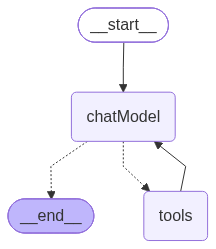

In [ ]:
from IPython.display import Image, display
# ReAct agent brain is llm so it is behaviong like agent
display(
    Image(graph.get_graph().draw_mermaid_png())
)

#### Adding memory in agentic graph

In [22]:
res=graph.invoke({"messages":["hello my name is div"]})
print(res["messages"][-1].content[0]["text"])

Hello Div! It's nice to meet you. How can I help you today?


In LangGraph, we can add memory to an agentic graph so the agent remembers previous messages across multiple interactions instead of treating every question as a new conversation.
There are two main types of memory:
1. Short-term memory — remembers messages within a conversation thread.
2. Long-term memory — remembers information across different conversation threads, even after the earlier conversation ends.
Let's start with short-term memory using your existing chatbot + tools graph.
1. Add short-term memory using a checkpointer
You already have a graph with chatModel, ToolNode, and tools_condition. The main change is to compile the graph with a checkpointer and pass a thread_id when invoking it.

In [17]:

from langgraph.graph import StateGraph, END, START, add_messages
from typing_extensions import TypedDict
from typing import Annotated
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.store.memory import InMemoryStore

from langchain.chat_models import init_chat_model
from langchain_tavily import TavilySearch
from langgraph.prebuilt import tools_condition, ToolNode

memory=InMemorySaver()
# long term memory
store=InMemoryStore()


def multiply(a:int,b:int)->int:
    """if any multiplication come use this tool"""
    return a*b

tools = [TavilySearch(max_results=2),multiply]

model = init_chat_model("google_genai:gemini-3.5-flash-lite")

# FIX 1: Store the model with tools bound to it
model_with_tools = model.bind_tools(tools)


class State(TypedDict):
    messages: Annotated[list, add_messages]


graph = StateGraph(State)


def chatModel(state: State):
    # FIX 2: Use model_with_tools, not model
    response = model_with_tools.invoke(state["messages"])
    return {"messages": [response]}


graph.add_node("chatModel", chatModel)
graph.add_node("tools", ToolNode(tools))

graph.add_edge(START, "chatModel")

graph.add_conditional_edges(
    "chatModel",
    tools_condition
)
# ReAct agent

graph.add_edge("tools", "chatModel")

# graph = graph.compile(checkpointer=memory,store=store)
graph = graph.compile(checkpointer=memory,store=store)


config={"configurable":{"thread_id":"1"}}
print(graph.get_state(config).values)
response = graph.invoke({
    "messages": [
        {"role": "user", "content": "my name is div"}

    ]
},config=config)
# print(graph.get_graph().draw_ascii())
print(response["messages"][-1].content[0]["text"])


{}
Hello Div! Nice to meet you. How can I help you today?


In [19]:
config={"configurable":{"thread_id":"1"}}

response = graph.invoke({
    "messages": [
        {"role": "user", "content": "what is my name"}

    ]
},
config=config)
# print(graph.get_graph().draw_ascii())
print(response["messages"][-1].content[0]["text"])


Your name is Div!


streaming in LangGraph using your existing ReAct agent with Gemini, Tavily, and the multiply tool.
The main idea is that instead of waiting for graph.invoke() to finish, you can receive updates while the graph is running.

In [20]:
# With stream_mode="updates", you receive each node's state update as that node finishes executing.

for chunk in graph.stream(
    {"messages":["Hii How are you"]},
    config=config,
    stream_mode="updates"
    ):
    print(chunk)
    # Remember: updates = node updates; messages = LLM message chunks; values = complete graph state after each step.


{'chatModel': {'messages': [AIMessage(content=[{'type': 'text', 'text': "Hello! I'm doing well, thank you for asking. How are you doing today, Div?", 'extras': {'signature': 'El8KXQFpFH0TAflq7hkT9ZwfDY5qfyc27y+zCn5sdIGF8BDJyWL32ykhqqb97r/Nyj8ygJlRSArN+OmkMD5ySsljZhphQsXC1GqhCZ5mBCHF9Hyh5PXzYmLSCb284MkT/A=='}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a12b26-a277-7923-9e75-24a744228808-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1582, 'output_tokens': 21, 'total_tokens': 1603, 'input_token_details': {'cache_read': 0}})]}}


In [21]:
for chunk in graph.stream(
    {"messages":["Hii How are you"]},
    config=config,
    stream_mode="values"
    ):
    print(chunk)

{'messages': [HumanMessage(content='my name is div', additional_kwargs={}, response_metadata={}, id='15cbe7f2-1eeb-429d-b7e3-ae70415962f5'), AIMessage(content=[{'type': 'text', 'text': 'Hello Div! Nice to meet you. How can I help you today?', 'extras': {'signature': 'El8KXQFpFH0T1rbJhccLsSGOcCfhSdXUNo6SfGFl71jyfHdVUrHLru93Q42EoO3KY+iaQkqTqDZ9+8iXEd/sOVzT2qSCyy8wFTb8xqK/jFSVi5NM2OOBIAGAM0pxubefpA=='}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a12b26-14e0-7a63-a468-d5fd10254f33-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1549, 'output_tokens': 15, 'total_tokens': 1564, 'input_token_details': {'cache_read': 0}}), HumanMessage(content='what is my name', additional_kwargs={}, response_metadata={}, id='f84642d6-a196-40a8-a02b-46438b5ca6c4'), AIMessage(content=[{'type': 'text', 'text': 'Your name is Div!', 'extras': {'signature':

In [22]:
for chunk in graph.stream(
    {"messages":["Hii what is my name"]},
    config=config,
    stream_mode="messages"
    ):
    print(chunk)

(AIMessageChunk(content=[{'type': 'text', 'text': 'Your name', 'index': 0}], additional_kwargs={}, response_metadata={'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a12b27-878f-7761-b1c6-6c0085eda88f', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1639, 'output_tokens': 2, 'total_tokens': 1641, 'input_token_details': {'cache_read': 0}}, tool_call_chunks=[]), {'thread_id': '1', 'ls_integration': 'langchain_chat_model', 'langgraph_step': 13, 'langgraph_node': 'chatModel', 'langgraph_triggers': ('branch:to:chatModel',), 'langgraph_path': ('__pregel_pull', 'chatModel'), 'langgraph_checkpoint_ns': 'chatModel:ec38cf2e-b6e3-c8aa-6667-fee50d10973d', 'checkpoint_ns': 'chatModel:ec38cf2e-b6e3-c8aa-6667-fee50d10973d', 'ls_provider': 'google_genai', 'ls_model_name': 'gemini-3.5-flash-lite', 'ls_model_type': 'chat', 'ls_temperature': None, 'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3', 'langchain-google-genai': '4.4.0'}})
(AIMessageC

Streaming lets you receive information while the graph is executing, instead of waiting for the entire graph to finish.
The 4 ways to get output
Method	What you receive
invoke()	Final graph state after execution completes
stream_mode="values"	Full current state after each graph step — previous + current messages
stream_mode="messages"	LLM output chunks as they're generated, along with metadata
stream_mode="updates"	State updates produced by each node after it executes
Imagine your graph
Your graph is:
START → chatModel → tools → chatModel → END
Suppose the user asks, "What is 2 × 3?"
invoke()

Wait for completion
You receive the final graph state after the model calls the tool and generates the answer.



values

Full state at each step
Previous messages + new messages, including tool calls and tool results when they are in the state.



messages

Live LLM output
For example, "The answer" → " is 6." as the model generates text chunks.



updates

Node-by-node updates
First chatModel produces a tool call, then tools returns 6, then chatModel produces the final answer.



One important distinction
messages streams chunks from the LLM, not necessarily the final, user-facing answer. If the LLM is generating a tool call, you may receive tool-call chunks too.
Also, values does not mean only previous + current user messages. It gives you the full current graph state, including whatever other state fields your graph maintains.
So your mental model is correct: values = state, messages = LLM chunks, updates = node updates.